# ДЗ №1 — Анализ данных
Шилов Глеб РИ-431001


## 1. Постановка задачи

### Бизнес-постановка

Для диплома я разрабатываю **BAS 2.0** — платформу breach-and-attack-simulation, которая будет **реально проводть атаки** (red-team). Платформа состоит из оркестратора и эксплуатирующих модулей.
Ключевая проблема для разработки модулей платформы: каждый день публикуются десятки новых CVE, и невозможно
вручную превращать каждую из них в рабочий эксплойт —
во многих случаях это будет бесполезная трата время, так как уязвимость не эксплуатируется в реальности (только в специфичных условиях возникает влияние уязвимости). Нужен инструмент, который по характеристикам CVE
(ещё до того, как кто-либо в мире подтвердил её реальную эксплуатацию) оценивает, **стоит ли вкладываться
в разработку атаки под эту уязвимость**.

### ML-постановка

Бинарная классификация: по признакам CVE (CVSS-метрики, тип уязвимости CWE, вендор/продукт, объём
описания, число ссылок в advisory и т.п.) предсказать метку

- **1** — CVE присутствует в CISA KEV (Known Exploited Vulnerabilities) — подтверждённая активная
  эксплуатация "в дикой природе";
- **0** — CVE в KEV не присутствует (на момент сборки каталога не зафиксирована активная эксплуатация).

KEV фиксирует только то, что уже подтверждено постфактум, а модель учится на этом сигнале, чтобы оценивать **остальную** (гораздо большую) массу CVE, включая свежие, которые в KEV ещё не успели попасть.

### Набор данных

1. **NVD (National Vulnerability Database)** — признаки: CVSS-метрики, CWE, вендор/продукт, даты,
   описание. Источник: community-реконструкция официальных JSON-фидов NVD,
   [`fkie-cad/nvd-json-data-feeds`](https://github.com/fkie-cad/nvd-json-data-feeds).
2. **CISA KEV catalog** — официальный список реально эксплуатируемых CVE,
   <https://www.cisa.gov/sites/default/files/feeds/known_exploited_vulnerabilities.json>
   (зеркало на GitHub: `cisagov/kev-data`).

Взят диапазон публикации **2016–2026 гг.** (для моей BAS системы я буду отбирать только относительно свежие уязвимости). Итоговый объём после очистки — **314 883 записи** (после удаления
`Rejected`-кандидатов CVE, которые не являются реальными уязвимостями), из них **1550** размечены как
KEV. Это 88% от всего каталога KEV (1754 записи) — оставшиеся 204 относятся к CVE, опубликованным до
2016 года, и не попадают в наше окно.
Это достаточный объём данных и достаточный уровень полноты по классу "1" для осмысленного EDA и последующего обучения модели.

## 2. Метрика качества

Классы сильно несбалансированы: доля KEV (класс 1) — **0.49%** от датасета. В такой ситуации
**accuracy неинформативна** — модель, всегда предсказывающая 0, уже даст ~99.5% accuracy и будет
бесполезна.

**Выбранная метрика: Recall (полнота) по классу 1, вместе с PR-AUC (Precision-Recall AUC) как основной
метрикой для сравнения моделей и порогов.**

Обоснование: для red-team-инструмента цена false negative (модель сказала "не стоит атаковать", а CVE
реально эксплуатируема) намного выше цены false positive (потратили немного времени на проверку CVE,
которая не особо перспективна) — пропущенная уязвимость означает упущенную возможность для атаки,
тогда как лишняя проверка - мое время. Поэтому recall приоритетнее precision. При этом только
recall легко "обмануть", предсказывая 1 почти всегда, — поэтому в паре с ним используется PR-AUC
(устойчива к дисбалансу классов, в отличие от ROC-AUC, которая на таком дисбалансе может выглядеть
обманчиво хорошей).


## 3.1 Данные: загрузка и подготовка

Код скачивает NVD JSON-фиды (2016–2026) и каталог CISA KEV,
парсит нужные признаки и строит единый датасет.


In [ ]:
import json, gc, lzma, urllib.request
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

YEARS = [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
NVD_URL_TMPL = "https://github.com/fkie-cad/nvd-json-data-feeds/releases/latest/download/CVE-{y}.json.xz"
KEV_URL = "https://raw.githubusercontent.com/cisagov/kev-data/main/known_exploited_vulnerabilities.json"


In [ ]:
def download(url: str) -> bytes:
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as r:
        return r.read()

def download_nvd_year(year: int) -> dict:
    raw_xz = download(NVD_URL_TMPL.format(y=year))
    raw_json = lzma.decompress(raw_xz)
    return json.loads(raw_json)


In [ ]:
def get_description(item):
    for d in item.get("descriptions", []):
        if d.get("lang") == "en":
            return d["value"]
    return ""

def get_cvss(item):
    metrics = item.get("metrics", {})
    for key in ["cvssMetricV31", "cvssMetricV30"]:
        entries = metrics.get(key, [])
        if entries:
            primary = next((e for e in entries if e.get("type") == "Primary"), entries[0])
            cd = primary["cvssData"]
            return {
                "cvss_version": cd.get("version"),
                "cvss_base_score": cd.get("baseScore"),
                "cvss_base_severity": cd.get("baseSeverity"),
                "cvss_attack_vector": cd.get("attackVector"),
                "cvss_attack_complexity": cd.get("attackComplexity"),
                "cvss_privileges_required": cd.get("privilegesRequired"),
                "cvss_user_interaction": cd.get("userInteraction"),
                "cvss_scope": cd.get("scope"),
                "exploitability_score": primary.get("exploitabilityScore"),
                "impact_score": primary.get("impactScore"),
            }
    entries = metrics.get("cvssMetricV2", [])
    if entries:
        primary = next((e for e in entries if e.get("type") == "Primary"), entries[0])
        cd = primary["cvssData"]
        return {
            "cvss_version": cd.get("version"),
            "cvss_base_score": cd.get("baseScore"),
            "cvss_base_severity": primary.get("baseSeverity"),
            "cvss_attack_vector": cd.get("accessVector"),
            "cvss_attack_complexity": cd.get("accessComplexity"),
            "cvss_privileges_required": cd.get("authentication"),
            "cvss_user_interaction": None,
            "cvss_scope": None,
            "exploitability_score": primary.get("exploitabilityScore"),
            "impact_score": primary.get("impactScore"),
        }
    return {k: None for k in ["cvss_version", "cvss_base_score", "cvss_base_severity",
                               "cvss_attack_vector", "cvss_attack_complexity",
                               "cvss_privileges_required", "cvss_user_interaction",
                               "cvss_scope", "exploitability_score", "impact_score"]}

def get_cwe(item):
    weaknesses = item.get("weaknesses", [])
    primary = next((w for w in weaknesses if w.get("type") == "Primary"), None)
    w = primary or (weaknesses[0] if weaknesses else None)
    if not w:
        return None
    for d in w.get("description", []):
        if d.get("lang") == "en":
            return d["value"]
    return None

def get_vendor_product(item):
    for aff in item.get("affected", []):
        for ad in aff.get("affectedData", []):
            v = ad.get("vendor")
            p = ad.get("product")
            if v and v.lower() not in ("n/a", "unknown"):
                return v, p
    return None, None

def item_to_row(item):
    vendor, product = get_vendor_product(item)
    desc = get_description(item)
    row = {
        "cve_id": item.get("id"),
        "published": item.get("published"),
        "last_modified": item.get("lastModified"),
        "vuln_status": item.get("vulnStatus"),
        "vendor": vendor,
        "product": product,
        "description": desc,
        "description_length": len(desc),
        "num_references": len(item.get("references", [])),
        "num_affected_entries": len(item.get("affected", [])),
        "cwe_id": get_cwe(item),
    }
    row.update(get_cvss(item))
    return row


In [ ]:
rows = []
for y in YEARS:
    data = download_nvd_year(y)
    items = data["cve_items"]
    rows.extend(item_to_row(it) for it in items)
    print(f"{y}: {len(items)} records (running total {len(rows)})")
    del data, items
    gc.collect()

nvd_df = pd.DataFrame(rows)
print("\nRAW shape:", nvd_df.shape)


2016: 10656 records (running total 10656)
2017: 17109 records (running total 27765)
2018: 17817 records (running total 45582)
2019: 17625 records (running total 63207)
2020: 21081 records (running total 84288)
2021: 23473 records (running total 107761)
2022: 27557 records (running total 135318)
2023: 31471 records (running total 166789)
2024: 39350 records (running total 206139)
2025: 45396 records (running total 251535)
2026: 78297 records (running total 329832)

RAW shape: (329832, 21)


In [ ]:
# убираем Rejected-уязвимости CVE (не являются реальными уязвимостями)
df = nvd_df[nvd_df["vuln_status"] != "Rejected"].copy()
print("После удаления Rejected:", df.shape)

# метка KEV
kev_raw = json.loads(download(KEV_URL))
kev_ids = {v["cveID"] for v in kev_raw["vulnerabilities"]}
print("KEV catalog size:", len(kev_ids), "| catalogVersion:", kev_raw["catalogVersion"])

df["is_kev"] = df["cve_id"].isin(kev_ids).astype(int)
df["published"] = pd.to_datetime(df["published"], errors="coerce")
df["year"] = df["published"].dt.year

matched = df["is_kev"].sum()
print(f"KEV CVEs, найденные в нашем окне NVD (2016-2026): {matched} из {len(kev_ids)} всего в каталоге")

df.to_csv("final_dataset.csv", index=False)
print("Сохранено final_dataset.csv, shape:", df.shape)


После удаления Rejected: (314883, 21)
KEV catalog size: 1754 | catalogVersion: 2026.10.20
KEV CVEs, найденные в нашем окне NVD (2016-2026): 1550 из 1754 всего в каталоге
Сохранено final_dataset.csv, shape: (314883, 23)


## 3.2. EDA: базовые статистики

In [6]:
print(df.shape)

(314883, 23)


314883 Уязвимостей
23 параметра оценки уязвимостей

In [7]:
df.dtypes

,0
cve_id,object
published,datetime64[ns]
last_modified,object
vuln_status,object
vendor,object
product,object
description,object
description_length,int64
num_references,int64
num_affected_entries,int64


In [8]:
miss = df.isna().sum().sort_values(ascending=False)
miss_pct = (miss / len(df) * 100).round(2)
pd.DataFrame({"missing": miss, "missing_%": miss_pct}).query("missing > 0")

,missing,missing_%
product,83735,26.59
vendor,83724,26.59
cvss_user_interaction,11581,3.68
cvss_scope,11581,3.68
cvss_attack_vector,11366,3.61
cvss_base_severity,11366,3.61
cvss_attack_complexity,11366,3.61
exploitability_score,11366,3.61
impact_score,11366,3.61
cvss_base_score,11366,3.61


У некоторого числа уязвимостей (26,59%) отсутсвует название вендора/продукта. Нужно учитывать при создавании модели

In [9]:
print(df["is_kev"].value_counts())
print()
print((df["is_kev"].value_counts(normalize=True) * 100).round(3).astype(str) + " %")

is_kev
0    313333
1      1550
Name: count, dtype: int64

is_kev
0    99.508 %
1     0.492 %
Name: proportion, dtype: object


Всего полпроцента уязвимостей размечены как эксплуатабельные. Accurancy не подойдет.

In [10]:
num_cols = ["cvss_base_score", "exploitability_score", "impact_score",
            "description_length", "num_references", "num_affected_entries"]
df[num_cols].describe()


,cvss_base_score,exploitability_score,impact_score,description_length,num_references,num_affected_entries
count,303517.000000,303517.000000,303517.000000,314883.00000,314883.000000,314883.000000
mean,7.057188,2.670925,4.236547,389.24074,4.053439,1.074612
std,1.694363,0.945525,1.547314,384.05441,5.144269,0.263910
min,0.000000,0.100000,0.000000,10.00000,1.000000,1.000000
25%,5.500000,1.800000,3.400000,192.00000,2.000000,1.000000
50%,7.200000,2.800000,3.600000,289.00000,2.000000,1.000000
75%,8.200000,3.900000,5.900000,457.00000,5.000000,1.000000
max,10.000000,10.000000,10.000000,3998.00000,294.000000,3.000000


In [11]:
df.groupby("is_kev")[num_cols].describe().T


is_kev                                  0            1
cvss_base_score      count  301967.000000  1550.000000
                     mean        7.050214     8.415806
                     std         1.693132     1.352482
                     min         0.000000     2.700000
                     25%         5.500000     7.625000
                     50%         7.200000     8.800000
                     75%         8.200000     9.800000
                     max        10.000000    10.000000
exploitability_score count  301967.000000  1550.000000
                     mean        2.669640     2.921290
                     std         0.945130     0.988539
                     min         0.100000     0.500000
                     25%         1.800000     1.800000
                     50%         2.800000     2.800000
                     75%         3.900000     3.900000
                     max        10.000000     3.900000
impact_score         count  301967.000000  1550.000000
                     mean        4.230627     5.389935
                     std         1.547086     1.093381
                     min         0.000000     1.400000
                     25%         3.400000     5.900000
                     50%         3.600000     5.900000
                     75%         5.900000     5.900000
                     max        10.000000     6.000000
description_length   count  313333.000000  1550.000000
                     mean      389.444307   348.089677
                     std       384.414880   299.760783
                     min        10.000000    34.000000
                     25%       192.000000   178.000000
                     50%       289.000000   271.000000
                     75%       457.000000   421.000000
                     max      3998.000000  3786.000000
num_references       count  313333.000000  1550.000000
                     mean        4.030444     8.701935
                     std         5.044111    14.531600
                     min         1.000000     2.000000
                     25%         2.000000     3.000000
                     50%         2.000000     5.000000
                     75%         5.000000     9.000000
                     max       294.000000   292.000000
num_affected_entries count  313333.000000  1550.000000
                     mean        1.074432     1.110968
                     std         0.263589     0.320298
                     min         1.000000     1.000000
                     25%         1.000000     1.000000
                     50%         1.000000     1.000000
                     75%         1.000000     1.000000
                     max         3.000000     3.000000

Медиана оценки CVSS выше у эксплуатированных уязвимостей.
Количество ссылок на статьи у уязвимостей в среднем в два раза больше у эксплуатированных уязвимостей.
Но если уязвимость только вышла, у нее будет 0-1 ссылок на статьи. Метрика не подходит для задачи

In [12]:
Кfor col in ["cvss_base_severity", "cvss_attack_vector", "vuln_status"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(10))


--- cvss_base_severity ---
cvss_base_severity
MEDIUM      130911
HIGH        123547
CRITICAL     41873
None         11366
LOW           7173
NONE            13
Name: count, dtype: int64

--- cvss_attack_vector ---
cvss_attack_vector
NETWORK             223716
LOCAL                70070
None                 11366
ADJACENT_NETWORK      7208
PHYSICAL              2523
Name: count, dtype: int64

--- vuln_status ---
vuln_status
Modified               166313
Analyzed                76207
Deferred                57576
Awaiting Analysis        7850
Received                 5981
Undergoing Analysis       956
Name: count, dtype: int64


In [22]:
print("Топ-10 Вендоров — все записи:")
print(df["vendor"].value_counts().head(10))
print("\nТоп-10 Вендоров — только KEV (is_kev=1):")
print(df.loc[df["is_kev"] == 1, "vendor"].value_counts().head(10))


Топ-10 Вендоров — все записи:
vendor
Linux                         17975
Microsoft                     12206
Oracle Corporation             8868
Google                         7386
IBM                            5895
Adobe                          5094
Apple                          4297
Cisco                          3391
Qualcomm, Inc.                 2730
Apache Software Foundation     2671
Name: count, dtype: int64

Топ-10 Вендоров — только KEV (is_kev=1):
vendor
Microsoft                     260
Apple                          89
Google                         80
Cisco                          61
Fortinet                       31
Microsoft Corporation          30
Apache Software Foundation     29
Oracle Corporation             28
Ivanti                         25
Adobe                          21
Name: count, dtype: int64


In [14]:
for col in ['cvss_base_severity', 'cvss_attack_vector', 'vuln_status']:
    print(f"\n--- {col} (KEV) ---")
    print(df[df['is_kev'] == 1][col].value_counts(dropna=False).head(10))



--- cvss_base_severity (KEV) ---
cvss_base_severity
HIGH        796
CRITICAL    576
MEDIUM      175
LOW           3
Name: count, dtype: int64

--- cvss_attack_vector (KEV) ---
cvss_attack_vector
NETWORK             1162
LOCAL                361
ADJACENT_NETWORK      24
PHYSICAL               3
Name: count, dtype: int64

--- vuln_status (KEV) ---
vuln_status
Analyzed               1544
Modified                  4
Deferred                  1
Undergoing Analysis       1
Name: count, dtype: int64


In [23]:
print("Топ-15 CWE — все записи:")
print(df["cwe_id"].value_counts().head(15))
print("\nТоп-15 CWE — только KEV (is_kev=1):")
print(df.loc[df["is_kev"] == 1, "cwe_id"].value_counts().head(15))

Топ-15 CWE — все записи:
cwe_id
CWE-79            41043
NVD-CWE-noinfo    29666
CWE-89            14648
CWE-787           13422
CWE-862           10139
CWE-125            9570
CWE-22             8473
CWE-416            8323
CWE-352            8183
CWE-20             7685
CWE-119            7108
CWE-200            6530
CWE-78             6039
CWE-476            5321
CWE-284            4926
Name: count, dtype: int64

Топ-15 CWE — только KEV (is_kev=1):
cwe_id
NVD-CWE-noinfo    250
CWE-787           129
CWE-78            108
CWE-22             86
CWE-416            82
CWE-502            68
NVD-CWE-Other      62
CWE-94             55
CWE-306            41
CWE-119            39
CWE-843            38
CWE-287            35
CWE-77             32
CWE-20             31
CWE-89             31
Name: count, dtype: int64


Присутсвует категория NVD-CWE-noinfo - отсутсвует

In [24]:
df.groupby(["year", "is_kev"]).size().unstack(fill_value=0)

is_kev,0,1
year,,
2016,5487,52
2017,13279,86
2018,15850,76
2019,16154,128
2020,17352,146
2021,19877,215
2022,24860,131
2023,28365,166
2024,39777,160


Во все годы есть эксплуатированные уязвимости. По абсолютному значению их число растатет - это подтверждает актуальность BAS 2.0 для проверки уязвимостей

## 3.3. EDA: визуализация

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
label_map = {0: "не в KEV", 1: "в KEV (эксплуатируется)"}
df["label"] = df["is_kev"].map(label_map)

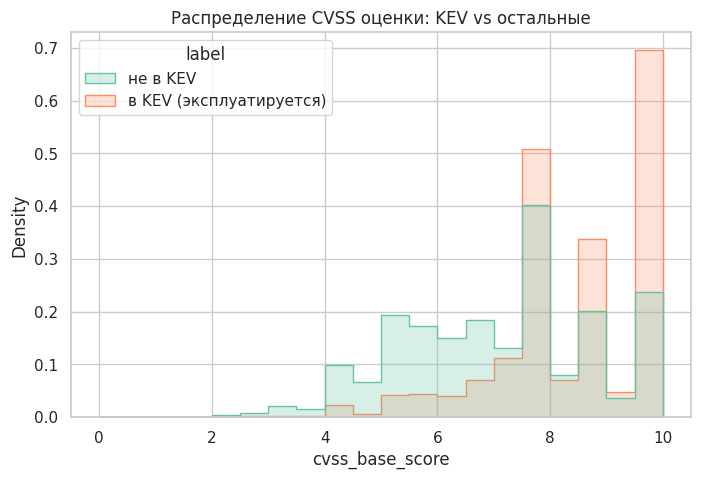

In [33]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df, x="cvss_base_score", hue="label", stat="density",
             common_norm=False, bins=20, element="step", ax=ax)
ax.set_title("Распределение CVSS оценки: KEV vs остальные")
plt.show()


Оба распределения смещены вправо (CVSS в среднем высокий у всех CVE — типичная
особенность NVD: низкие по серьёзности уязвимости CNA часто не заводят как отдельные CVE).
Но форма разная: у KEV ярко выраженный пик у верхней границы шкалы (9–10), у остального датасета — более размазанное распределение с заметной массой в районе 5–7. При этом справа от CVSS=7 присутствуют
оба класса в сопоставимых пропорциях — то есть высокий CVSS необходим, но не достаточен для реальной эксплуатации: среди CVE с высоким CVSS подавляющее большинство (по числу) в KEV всё равно не попадает.
Значит, порогового правила "CVSS ≥ 9 → атаковать" недостаточно, нужна модель, учитывающая и другие
признаки.

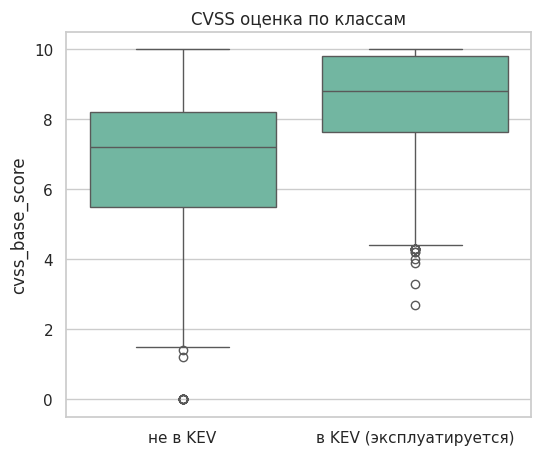

In [35]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=df, x="label", y="cvss_base_score", ax=ax)
ax.set_title("CVSS оценка по классам")
ax.set_xlabel("")
plt.show()

**Комментарий.** Медиана CVSS у KEV заметно выше (8.8 против 7.2 у остальных), межквартильный размах у KEV уже и целиком лежит в верхней части шкалы (7.6–9.8).
Интереснее выбросы снизу: несколько CVE из KEV имеют CVSS всего 2.7–4.4 — формально "некритичные", но реально эксплуатируемые. Это аргумент за то, чтобы не отбрасывать low/medium CVSS уязвимости как заведомо неинтересные.

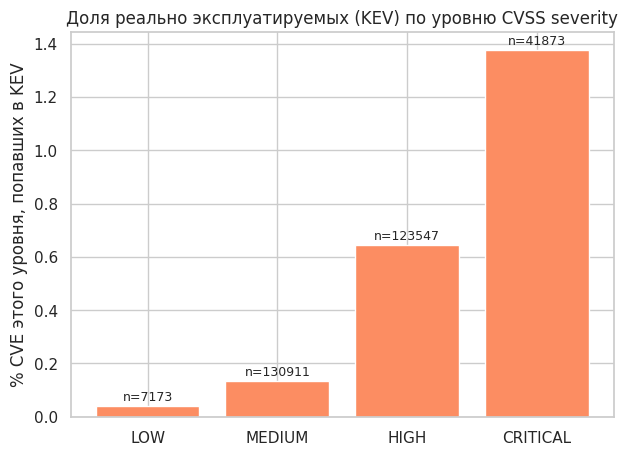

In [36]:
sev_order = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
tmp = df[df["cvss_base_severity"].isin(sev_order)]
share = tmp.groupby("cvss_base_severity")["is_kev"].mean().reindex(sev_order) * 100
counts = tmp.groupby("cvss_base_severity").size().reindex(sev_order)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(sev_order, share.values, color=sns.color_palette("Set2")[1])
for b, c in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.02, f"n={c}", ha="center", fontsize=9)
ax.set_ylabel("% CVE этого уровня, попавших в KEV")
ax.set_title("Доля реально эксплуатируемых (KEV) по уровню CVSS severity")
plt.show()


**Комментарий.** Чёткий монотонный рост доли KEV от LOW (0.04%) к CRITICAL (1.38%).
Но если смотреть на абсолютные числа: даже среди 41 873 CRITICAL-уязвимостей реально эксплуатируется лишь **~1.4%**. Это количественно подтверждает мысль из обсуждения постановки задачи: CVSS/severity — полезный, но слабый предиктор активной эксплуатации сам по себе, и именно поэтому задача приоритизации
нетривиальна и оправдывает отдельную ML-модель, а не фильтр по severity.


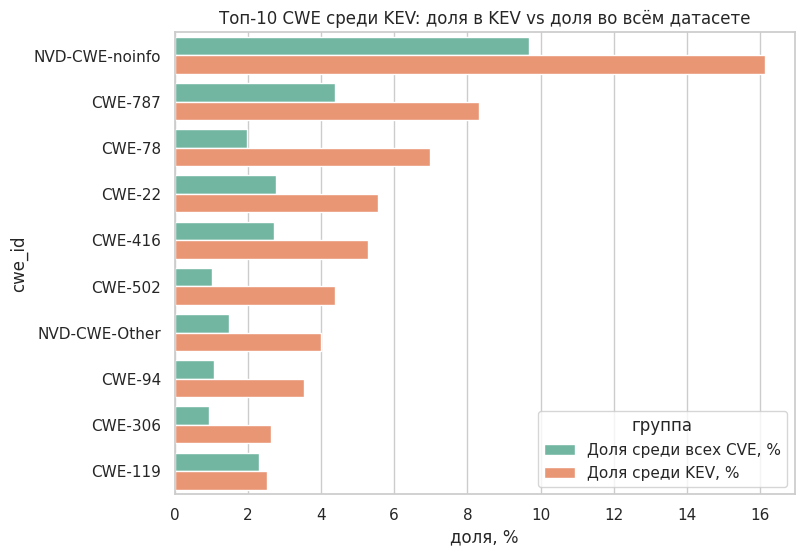

In [37]:
top_cwe_kev = df.loc[df["is_kev"] == 1, "cwe_id"].value_counts().head(10)
cwe_list = top_cwe_kev.index.tolist()
overall_share = (df["cwe_id"].value_counts(normalize=True).reindex(cwe_list) * 100)
kev_share = (top_cwe_kev / df["is_kev"].sum() * 100)
plot_df = (pd.DataFrame({"Доля среди всех CVE, %": overall_share, "Доля среди KEV, %": kev_share})
           .reindex(cwe_list).reset_index().rename(columns={"index": "cwe_id"})
           .melt(id_vars="cwe_id", var_name="группа", value_name="доля, %"))

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=plot_df, y="cwe_id", x="доля, %", hue="группа", order=cwe_list, ax=ax)
ax.set_title("Топ-10 CWE среди KEV: доля в KEV vs доля во всём датасете")
plt.show()


**Комментарий.** Для нескольких типов уязвимостей доля в KEV заметно выше их доли в датасете NVD
- CWE-502 Deserialization (1.0% → 4.4%, ×4.3),
- CWE-78 OS Command Injection (2.0% → 7.0%, ×3.5),
- CWE-94 Code Injection (1.1% → 3.5%, ×3.3),
- CWE-306 Missing Authentication (0.9% → 2.6%, ×2.8).

Это ровно те классы уязвимостей, которые дают атакующему прямое выполнение кода
или обход аутентификации — логично, что их охотнее эксплуатируют.
CWE — категориальный признак с большим числом возможных значений, причём большая часть значений редкая: встречается в обучающей выборке по 1–2 раза. Поэтому использовать только CWE для модели не лучшая идея - модели попросту не на чем будет учиться по редким категориям.


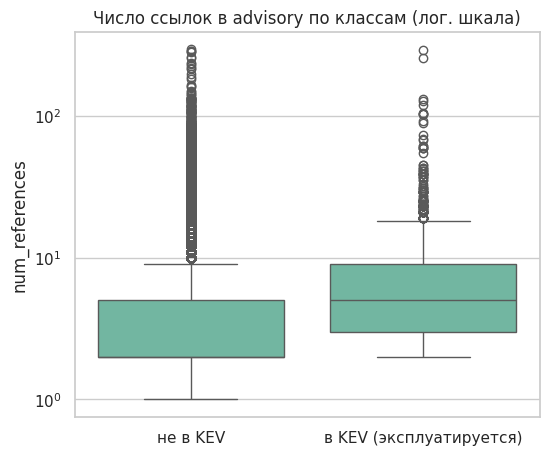

In [38]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=df, x="label", y="num_references", ax=ax)
ax.set_yscale("log")
ax.set_title("Число ссылок в advisory по классам (лог. шкала)")
ax.set_xlabel("")
plt.show()

**Комментарий.** У KEV медиана числа ссылок выше (5 против 2), и разброс шире. Но тут нужна осторожность, которую стоит явно проговорить как методологический риск: `num_references` считается на **текущий** момент (дата скачивания данных), а не на момент принятия решения "атаковать/не атаковать".
После того как уязвимость попадает в KEV, про неё обычно пишут дополнительные статьи, добавляют ссылки на PoC/разборы — то есть часть сигнала в этом признаке может появляться уже **после** факта эксплуатации (ссылки дополняются позднее заведения CVE в NTD).
Для честного обучения модели этот признак нужно будет либо
исключить, либо пересчитывать по состоянию на фиксированное окно (например, N дней после публикации CVE), а не брать "как есть" на дату сборки датасета.


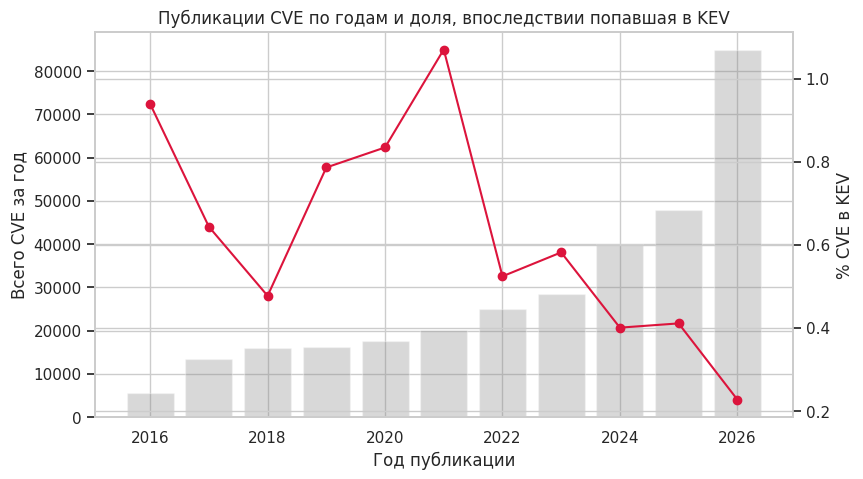

In [39]:
df["year"] = df["published"].dt.year
yearly = df.groupby("year").agg(total=("cve_id", "size"), kev=("is_kev", "sum"))
yearly["share_pct"] = yearly["kev"] / yearly["total"] * 100

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.bar(yearly.index, yearly["total"], alpha=0.3, color="gray")
ax1.set_ylabel("Всего CVE за год")
ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly["share_pct"], color="crimson", marker="o")
ax2.set_ylabel("% CVE в KEV")
ax1.set_title("Публикации CVE по годам и доля, впоследствии попавшая в KEV")
ax1.set_xlabel("Год публикации")
plt.show()

С 2022 по 2026 год доля CVE, попавших в KEV, устойчиво снижается: 0.52% → 0.58% → 0.40% → 0.41% → **0.23%**. Это не значит, что CVE 2026 года объективно безопаснее — скорее это эффект "незрелости" метки (в KEV еще не завели): чтобы CVE попала в KEV, кто-то сначала должен её реально проэксплуатировать, а CISA —
это зафиксировать, и на это нужно время (от месяцев до нескольких лет). У свежих CVE этого времени попросту не было.

Практическое следствие для дальнейшей работы:
1. Не стоит делать обучение по всему датасету — модель будет переобучаться на
  "задним числом" известных паттернах и давать завышенные метрики на валидации, а на по-настоящему новых CVE (ради которых всё и затевалось) работать хуже. Нужен разделять уязвимости по времени для обучения (например, train — CVE до 2023 года, test — 2024+).
2. CVE последних ~6–12 месяцев стоит либо исключить из обучения, либо использовать с осторожностью — их текущая метка "0" ненадёжна (это не "безопасно", а "ещё не успели понаблюдать").
3. Тот же эффект частично объясняет и наблюдение по `num_references` (fig 5) — оба признака связаны с "возрастом" CVE и временем, которое было у сообщества на реакцию.

---
### Итоговые выводы по EDA (для дальнейшего обучения)

- **Сильный дисбаланс классов** (0.49% KEV) → при обучении стоит взять порог по PR-кривой, не accuracy.
- **Пропуски**: vendor/product — 26.6% (структура `affected` в части записей не даёт явного вендора нужно восстанавливать из CPE или оставлять как "unknown"); CVSS и производные — 3.6% (записи без оценки CVSS от NVD); CWE — 2.7%, плюс отдельная категория `NVD-CWE-noinfo`, которую стоит трактовать как "неизвестно".
- **Severity/CVSS — полезный, но слабый predictor сам по себе**: даже среди CRITICAL лишь ~1.4% в KEV.
- **CWE-признак информативен** (deserialization, command/code injection, missing auth дают 3–4-кратное превышение доли по сравнению NVD) — кандидат на приоритетный признак, но есть много вариантов, встретитившихся 1-2 раза, нужна группировка.
- **Риск использования** `num_references`. Ссылки на Poc`и появляются позднее анонсирования уязвимости. Если активно ее использовать в модели, предсказания могут плохо работать для новых уязвимостей. Возможно стоит разделить на два датасета по времени, или учитывать дату выпуска уязвимости при принятии решения.
